### Setups

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
from sklearn.metrics import confusion_matrix, f1_score
import pandas as pd

os.makedirs("../figures/confusion_matrix_cold_start", exist_ok=True)

LABELS_RAW = [9, 10, 11]     
ORDER = [2, 1, 0]
NAMES = ["prefer warmer", "no change", "prefer cooler"]

#TICK_COLOR = {"prefer warmer": "red", "no change": "green", "prefer cooler": "blue"}

import matplotlib.colors as mcolors
import colorsys

def darken(hex_color, factor=0.7):
    # factor < 1 darkens, factor > 1 lightens
    r, g, b = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    l = max(0, min(1, l * factor))
    r, g, b = colorsys.hls_to_rgb(h, l, s)
    return mcolors.to_hex((r, g, b))

TICK_COLOR = {
    "prefer warmer": darken("#EF6A72", 0.75),
    "no change":     darken("#B0BEC5", 0.6),
    "prefer cooler": darken("#81AFE4", 0.75),
}

### Load data

In [2]:
# PersonAI
personai_results_path = "../../PCM/results/personai/"
#P_MAJ_SUM = "pcm_models_results/personai/majority_class_parrot_summary.json"
#P_MAJ_ALL = "pcm_models_results/personai/majority_class_parrot_all_user_results.json"
personai_best_exp = "../../Experiments/PersonAI_cold/PersonAI_cold_swls_score"
P_PCM_SUM = f"../../PCM/results/personai/random_forest_summary.json"        
P_PCM_ALL = "../../PCM/results/personai/random_forest_all_user_results.json"

# DORN
dorn_results_path = "../../PCM/results/dorn/"
#D_MAJ_SUM = "pcm_models_results/dorn/majority_class_parrot_summary.json"
#D_MAJ_ALL = "pcm_models_results/dorn/majority_class_parrot_all_user_results.json" 
dorn_best_exp = "../../Experiments/dorn_cold/dorn_cold_emotional_stability"
D_PCM_SUM = f"../../PCM/results/dorn/random_forest_summary.json"        
D_PCM_ALL = "../../PCM/results/dorn/random_forest_all_user_results.json"

### finding the best PCM model

In [3]:
#finding the best PCM model for PersonAI and DORN based on the average F1 macro (however we set both to random_forest)
personai_best_pcm = None

for file in Path(personai_results_path).glob("*_summary.json"):
    with open(file, "r") as f:
        data = json.load(f)

    if "average_f1_macro_over_all_folds_and_all_users" not in data:
        continue

    score = data["average_f1_macro_over_all_folds_and_all_users"]

    if personai_best_pcm is None or score > personai_best_pcm["score"]:
        personai_best_pcm = {"file": file.name, "score": score}

print(personai_best_pcm)



dorn_best_pcm = None

for file in Path(dorn_results_path).glob("*_summary.json"):
    with open(file, "r") as f:
        data = json.load(f)

    if "average_f1_macro_over_all_folds_and_all_users" not in data:
        continue

    score = data["average_f1_macro_over_all_folds_and_all_users"]

    if dorn_best_pcm is None or score > dorn_best_pcm["score"]:
        dorn_best_pcm = {"file": file.name, "score": score}

print(dorn_best_pcm)



{'file': 'random_forest_summary.json', 'score': 0.42122602984820234}
{'file': 'random_forest_classifier_with_standard_scaler_summary.json', 'score': 0.5426450504246817}


### finding the most (im)balanced and best users (PCM)

In [4]:
def most_imbalanced_users(all_user_path, k=2):
    d = json.load(open(all_user_path))
    scores = []

    for u, data in d["all_users_results"].items():
        cm = np.array(data["confusion_matrix_over_all_folds"])
        class_counts = cm.sum(axis=1)
        proportions = class_counts / class_counts.sum()
        scores.append((u, proportions.max()))

    scores.sort(key=lambda x: x[1], reverse=True)
    return [u for u, _ in scores[:k]]

def most_balanced_users(all_user_path, k=2):
    d = json.load(open(all_user_path))
    scores = []

    for u, data in d["all_users_results"].items():
        cm = np.array(data["confusion_matrix_over_all_folds"])
        class_counts = cm.sum(axis=1)
        proportions = class_counts / class_counts.sum()
        scores.append((u, proportions.std()))

    scores.sort(key=lambda x: x[1])
    return [u for u, _ in scores[:k]]

def best_users_by_macro_f1(all_user_path, k=2):
    d = json.load(open(all_user_path, "r", encoding="utf-8"))
    users = d["all_users_results"]
    ranked = sorted(users.keys(),
                    key=lambda u: users[u]["average_f1_macro_over_all_folds"],
                    reverse=True)
    return ranked[:k]


In [5]:
pcm_personai_balanced_users = most_balanced_users(P_PCM_ALL, k=3)
pcm_personai_imbalanced_users = most_imbalanced_users(P_PCM_ALL, k=3)    
pcm_personai_best_users = best_users_by_macro_f1(P_PCM_ALL, k=3)

print("PersonAI imbalanced:", pcm_personai_imbalanced_users)
print("PersonAI balanced:", pcm_personai_balanced_users)
print("PersonAI best by macro F1:", pcm_personai_best_users)


pcm_dorn_balanced_users = most_balanced_users(D_PCM_ALL, k=3)
pcm_dorn_imbalanced_users = most_imbalanced_users(D_PCM_ALL, k=3)    
pcm_dorn_best_users = best_users_by_macro_f1(D_PCM_ALL, k=3)

print("DORN imbalanced:", pcm_dorn_imbalanced_users)
print("DORN balanced:", pcm_dorn_balanced_users)
print("DORN best by macro F1:", pcm_dorn_best_users)

PersonAI imbalanced: ['id061', 'id056', 'id077']
PersonAI balanced: ['id064', 'id037', 'id070']
PersonAI best by macro F1: ['id084', 'id061', 'id056']
DORN imbalanced: ['dorn10', 'dorn14', 'dorn16']
DORN balanced: ['dorn7', 'dorn4', 'dorn19']
DORN best by macro F1: ['dorn1', 'dorn12', 'dorn13']


### finding the best cohort model

In [6]:
def evaluate_experiment(dataset_name, exp_path, baseline=False, majority=False):
    exp_path = Path(exp_path)

    all_true = []
    all_pred = []

    for iter_dir in exp_path.iterdir():
        if not iter_dir.is_dir():
            continue

        if dataset_name.lower() == "personai":
            if baseline:
                csv_files = list(iter_dir.glob("*_baseline_predictions.csv"))
            else:
                csv_files = list(iter_dir.glob("*_cluster_predictions.csv"))
        elif dataset_name.lower() == "dorn":
            if baseline:
                csv_files = list(iter_dir.glob("*_baseline_predictions.csv"))
            else:
                csv_files = list(iter_dir.glob("*_cluster_predictions.csv"))
        if not csv_files:
            continue

        df = pd.read_csv(csv_files[0])
        if majority:
            all_true.extend(df["true"])
            all_pred.extend(df["majority_pred"])
        else:
            all_true.extend(df["true"])
            all_pred.extend(df["pred"])

    cm = confusion_matrix(all_true, all_pred, labels=[9,10,11])
    macro_f1 = f1_score(all_true, all_pred, average="macro")

    return cm, macro_f1


In [7]:
dorn_best_cm, dorn_best_f1 = 0, 0
personai_best_cm, personai_best_f1 = 0, 0
'''for exp in Path(r"cohort_experiments/dorn").iterdir():
    if exp.is_dir():
        cm, f1 = evaluate_experiment("dorn", exp)
        if f1 > dorn_best_f1:
            dorn_best_cm = cm
            dorn_best_f1 = f1
            dorn_best_exp = exp

#D_BEST_COHORT_ALL = f"{dorn_best_exp}\meta.json"

for exp in Path(r"cohort_experiments/personai").iterdir():
    if exp.is_dir() and not "cold" in str(exp):
        cm, f1 = evaluate_experiment("personai", exp)
        if f1 > personai_best_f1:
            personai_best_cm = cm
            personai_best_f1 = f1
            personai_best_exp = exp'''


dorn_best_cm, dorn_best_f1 = evaluate_experiment("dorn", dorn_best_exp)
dorn_baseline_cm, dorn_baseline_f1 = evaluate_experiment("dorn", dorn_best_exp, baseline=True)
dorn_majority_cm, dorn_majority_f1 = evaluate_experiment("dorn", dorn_best_exp, majority=True)
D_BEST_COHORT_ALL = f"{dorn_best_exp}/meta.json"


personai_best_cm, personai_best_f1 = evaluate_experiment("personai", personai_best_exp)
personai_baseline_cm, personai_baseline_f1 = evaluate_experiment("personai", personai_best_exp, baseline=True)
personai_majority_cm, personai_majority_f1 = evaluate_experiment("personai", personai_best_exp, majority=True)
P_BEST_COHORT_ALL = f"{personai_best_exp}/meta.json"

print("Dorn Results:")
print(" Experiment Path:", dorn_best_exp)
print(" Macro F1:", dorn_best_f1)
print("PersonAI Results(best):")
print(" Experiment Path:", personai_best_exp)
print(" Macro F1:", personai_best_f1)
print("PersonAI Baseline Results:")
print(" Macro F1:", personai_baseline_f1)
print("PersonAI Majority Results:")
print(" Macro F1:", personai_majority_f1)

Dorn Results:
 Experiment Path: ../../Experiments/dorn_cold/dorn_cold_emotional_stability
 Macro F1: 0.37821956306340737
PersonAI Results(best):
 Experiment Path: ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score
 Macro F1: 0.33172107238351184
PersonAI Baseline Results:
 Macro F1: 0.31375746984566083
PersonAI Majority Results:
 Macro F1: 0.2787419182344077


### helper functions

In [8]:
def plot_cm(cm_raw, title, filename=None):
    cm = np.array(cm_raw)[ORDER][:, ORDER]

    plt.figure(figsize=(5,5))
    im = plt.imshow(cm, cmap="Greys")

    #plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")

    plt.xticks(range(3), NAMES, rotation=45, ha="right")
    plt.yticks(range(3), NAMES)

    ax = plt.gca()
    for t in ax.get_xticklabels(): t.set_color(TICK_COLOR[t.get_text()])
    for t in ax.get_yticklabels(): t.set_color(TICK_COLOR[t.get_text()])

    threshold = cm.max() / 2.0
    for i in range(3):
        for j in range(3):
            color = "white" if cm[i, j] > threshold else "black"
            plt.text(j, i, int(cm[i, j]),
                     ha="center", va="center",
                     color=color)
    plt.xticks(rotation=90)

    plt.tight_layout()

    if filename:
        plt.savefig(f"../figures/confusion_matrix_cold_start/{filename}.pdf", dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()


def load(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)
    
def plot_full(summary_path, title, filename=None):
    s = load(summary_path)
    plot_cm(s["confusion_matrix_over_all_folds_and_all_users"], title, filename=filename)

def plot_examples(dataset_name, model_name, all_user_path=None, n_users=2, users=None, filename=None, cohorts=False, exp_path=None, baseline=False, majority=False):
    d = load(all_user_path)
    if users is None:
        users = list(d["all_users_results"].keys())[:n_users] if not cohorts else d["test_ids"][:n_users]
    else:
        users = users[:n_users]

    if not cohorts:
        for u in users:
            cm_u = d["all_users_results"][u]["confusion_matrix_over_all_folds"]
            plot_cm(cm_u, f"{dataset_name} – {model_name} – User {u}",
                    filename=f"{filename}_{u}" if filename else None)

    else:
        exp_path = Path(exp_path)
        all_dfs = []
        for iter_dir in exp_path.iterdir():
            if not iter_dir.is_dir():
                continue

            if baseline:
                csv_files = list(iter_dir.glob("*_baseline_predictions.csv"))
            else:
                csv_files = list(iter_dir.glob("*_cluster_predictions.csv"))
            if not csv_files:
                csv_files = []

            if csv_files:
                df = pd.read_csv(csv_files[0])
                df.columns = df.columns.str.strip().str.replace("\ufeff", "")
                all_dfs.append(df)

        df_all = pd.concat(all_dfs, ignore_index=True)

        for u in users:
            df_u = df_all[df_all["user"] == u]
            if majority:
                cm_u = confusion_matrix(df_u["true"].astype(int), df_u["majority_pred"].astype(int), labels=[9, 10, 11])
            else:
                cm_u = confusion_matrix(df_u["true"].astype(int), df_u["pred"].astype(int), labels=[9, 10, 11])
            plot_cm(cm_u, f"{dataset_name} – {model_name} – User {u}",
                    filename=f"{filename}_{u}" if filename else None)

### Full dataset confusion matrices

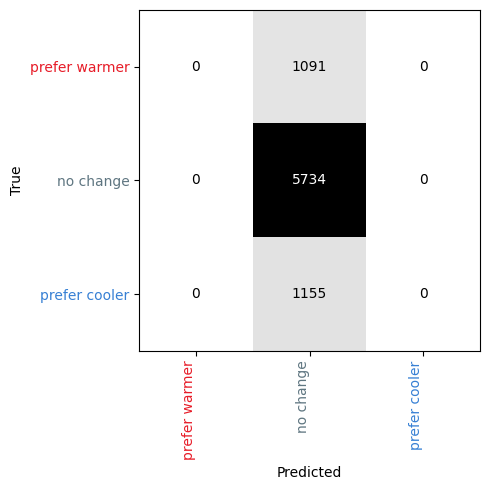

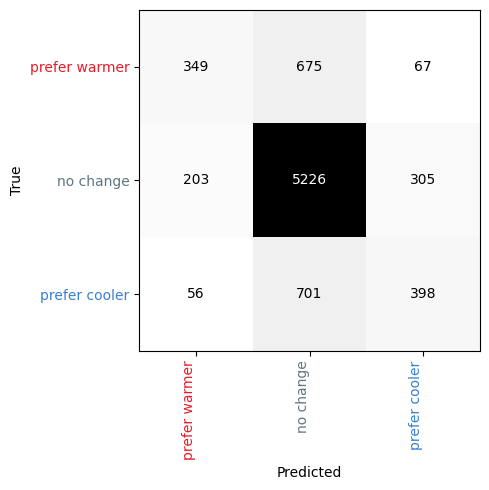

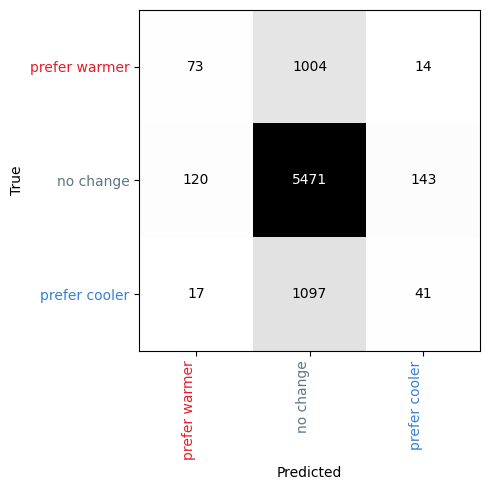

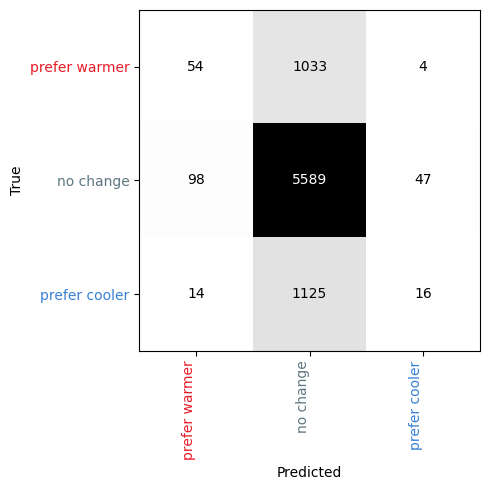

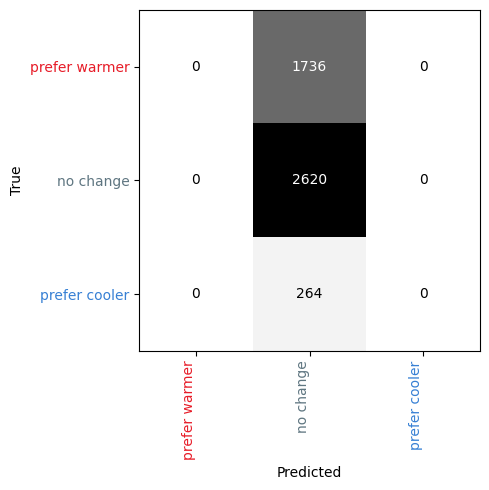

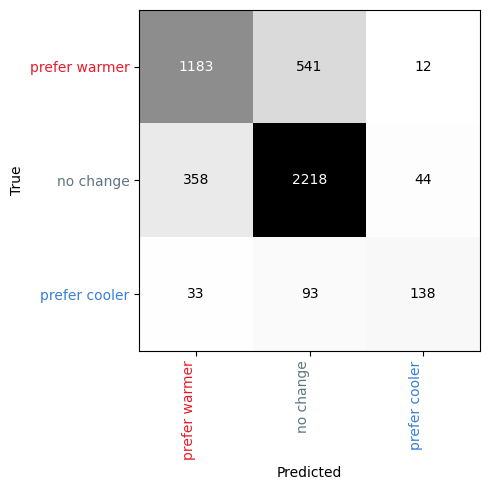

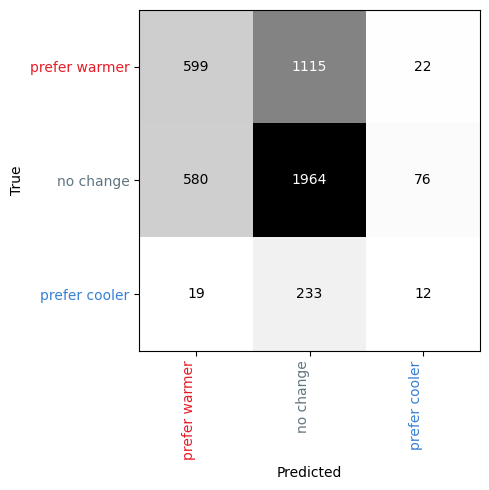

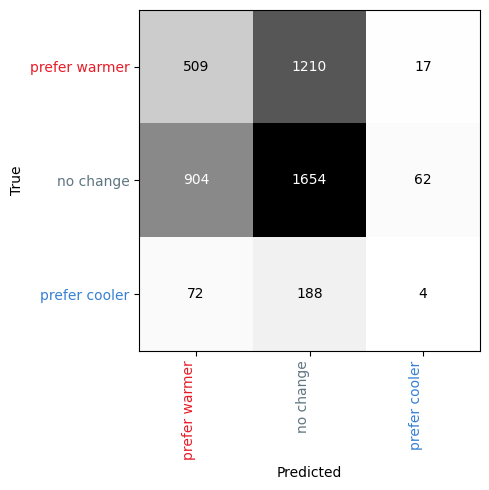

In [9]:
# PersonAI full
plot_cm(personai_majority_cm,  "PersonAI – Majority Class (full)", filename="personai_confusion_matrix_majority_class_full")
plot_full(P_PCM_SUM,  "PersonAI – Personal Comfort Model (full)", filename="personai_confusion_matrix_pcm_full")
plot_cm(personai_best_cm, "PersonAI – Cross-Dist Cohort Model (full)", filename="personai_confusion_matrix_cross_dist_cohort_model_full")
plot_cm(personai_baseline_cm, "PersonAI – Baseline Cohort (full)", filename="personai_confusion_matrix_baseline_cohort_full")

# DORN full
plot_cm(dorn_majority_cm,  "DORN – Majority Class (full)", filename="dorn_confusion_matrix_majority_class_full")
plot_full(D_PCM_SUM,  "DORN – Personal Comfort Model (full)", filename="dorn_confusion_matrix_pcm_full")
plot_cm(dorn_best_cm, "DORN – Cross-Dist Cohort Model (full)", filename="dorn_confusion_matrix_cross_dist_cohort_model_full")
plot_cm(dorn_baseline_cm, "DORN – Baseline Cohort (full)", filename="dorn_confusion_matrix_baseline_cohort_full")

### Per person examples

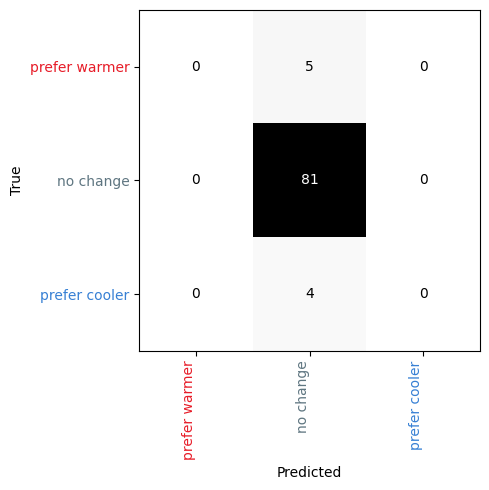

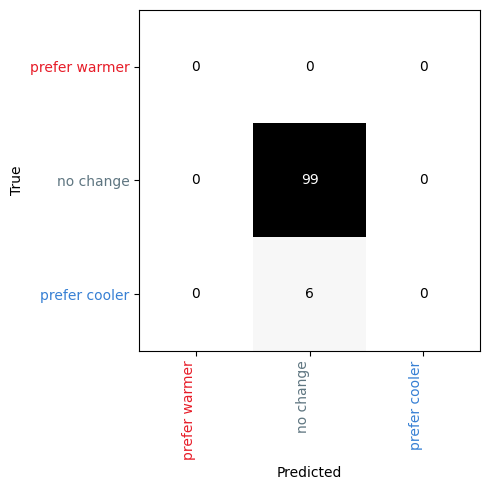

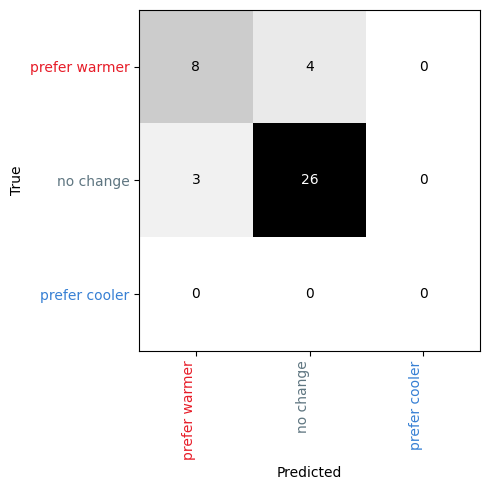

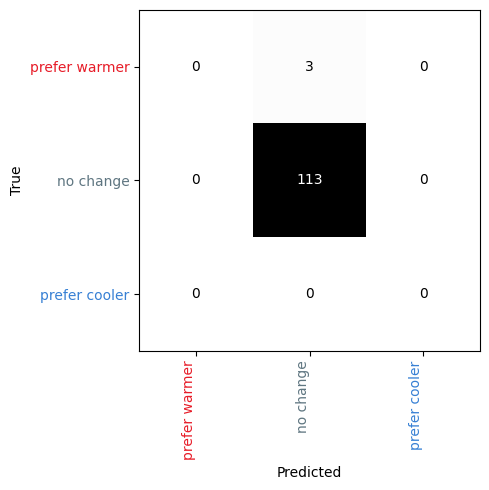

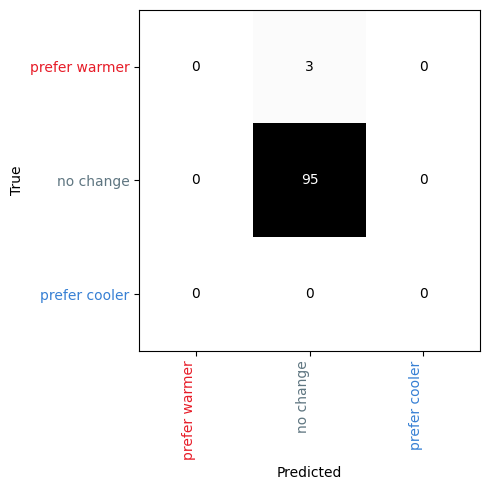

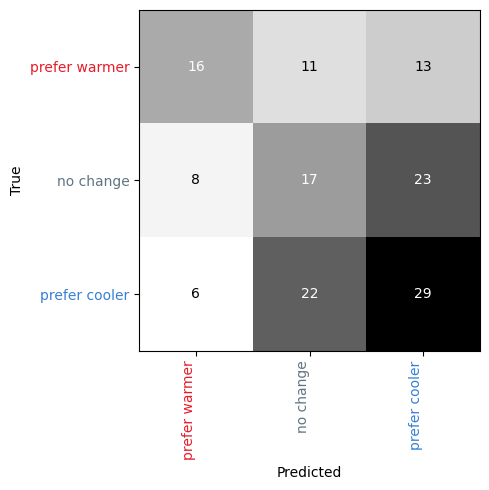

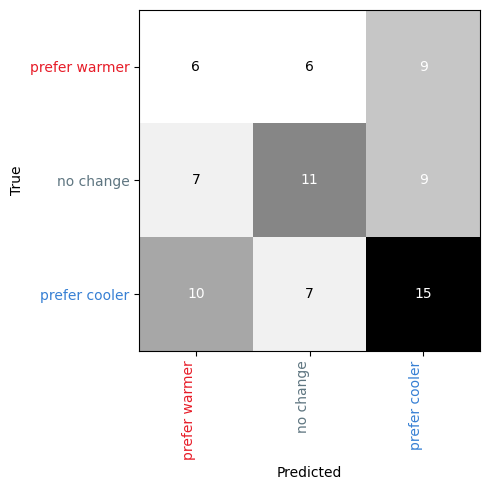

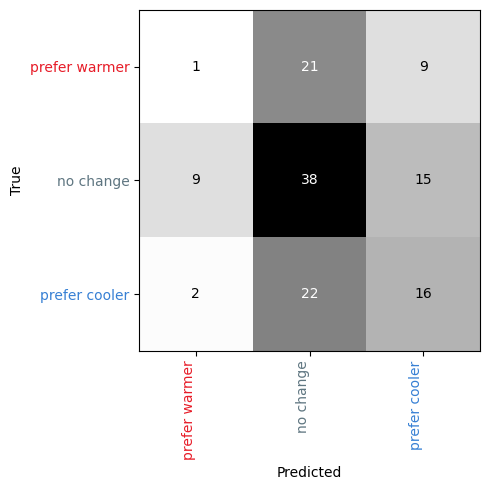

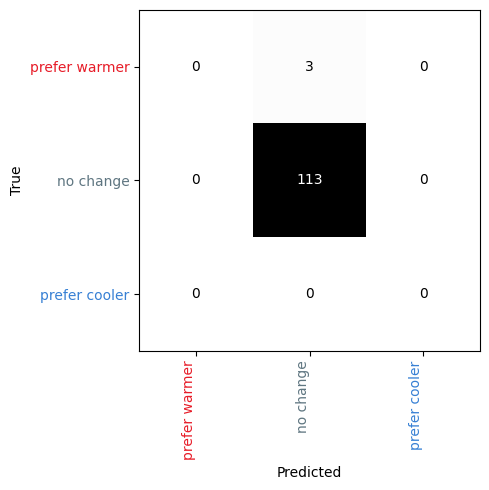

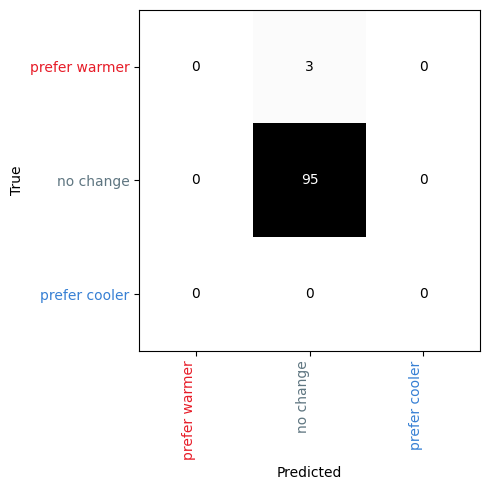

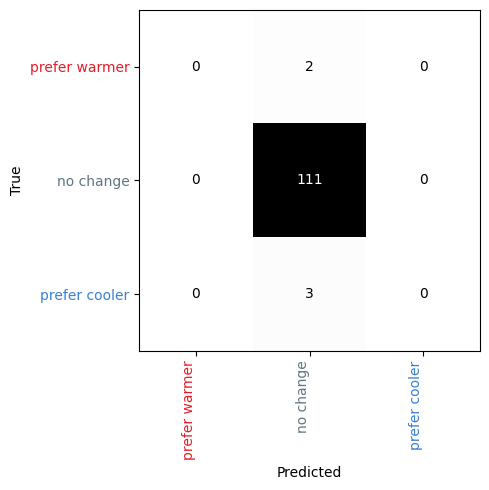

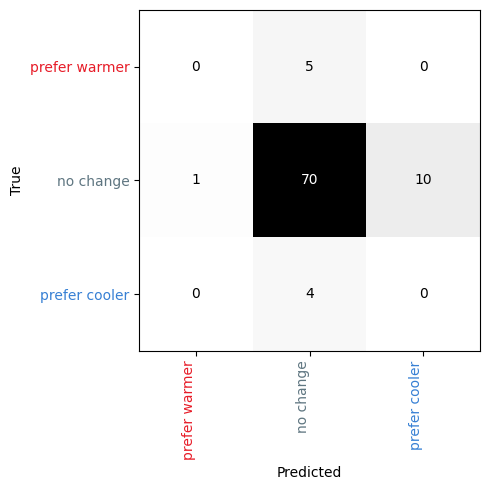

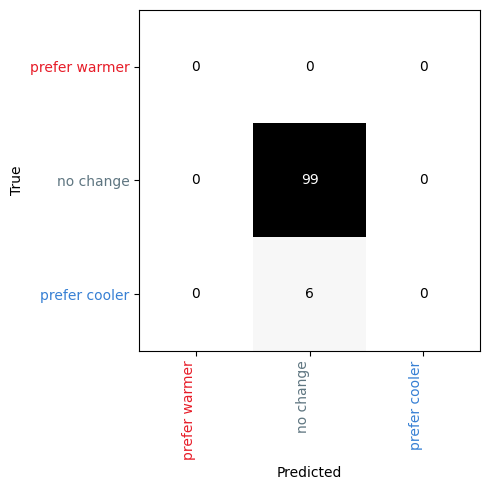

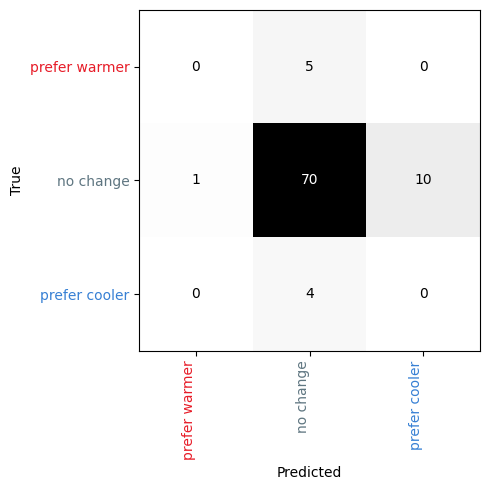

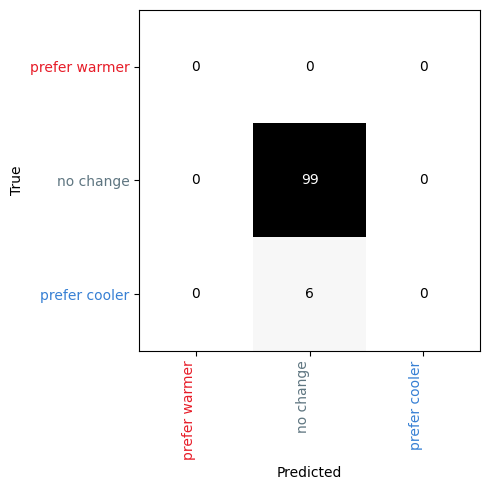

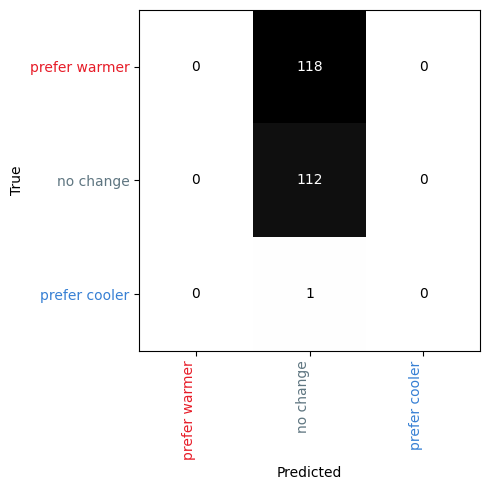

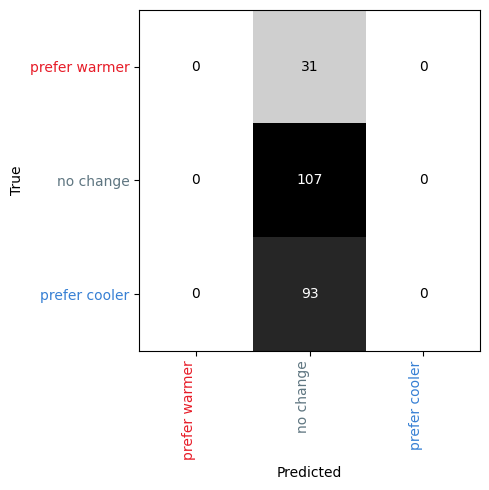

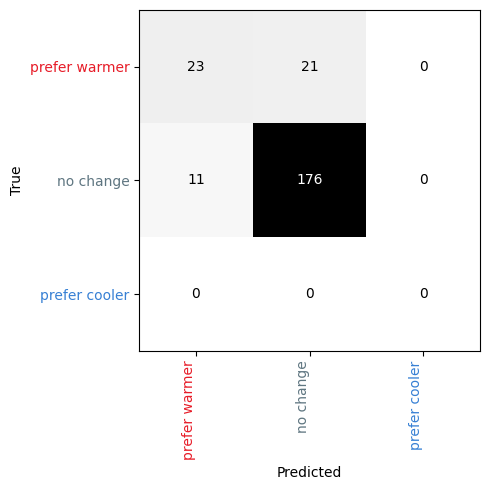

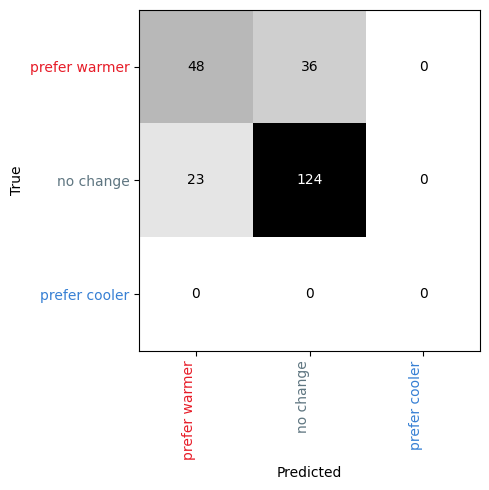

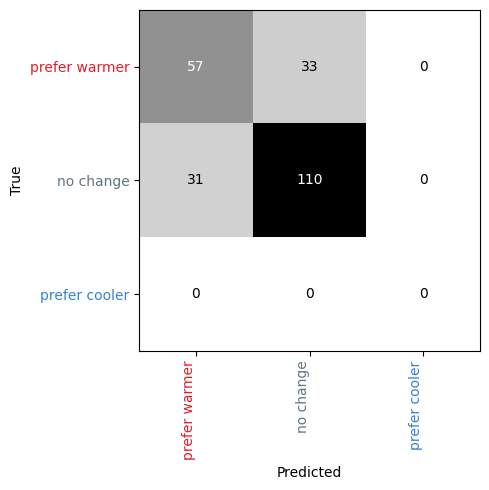

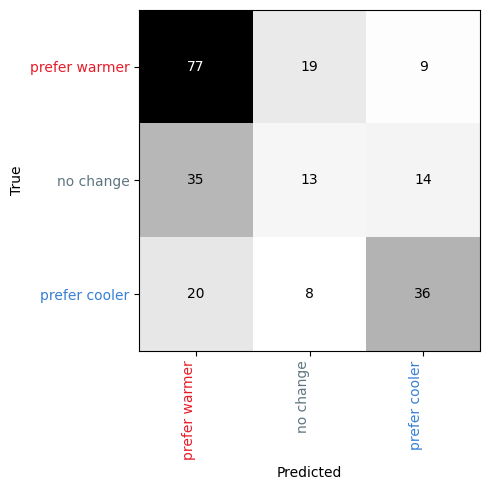

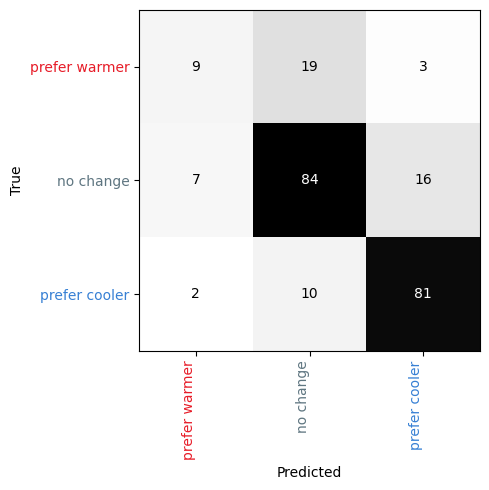

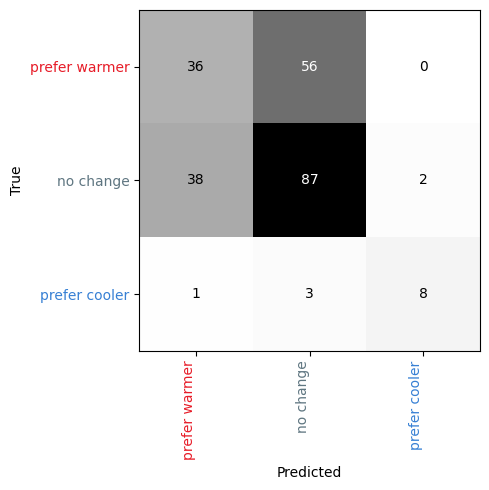

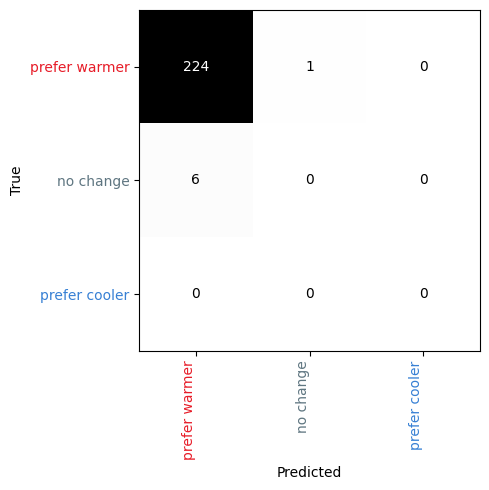

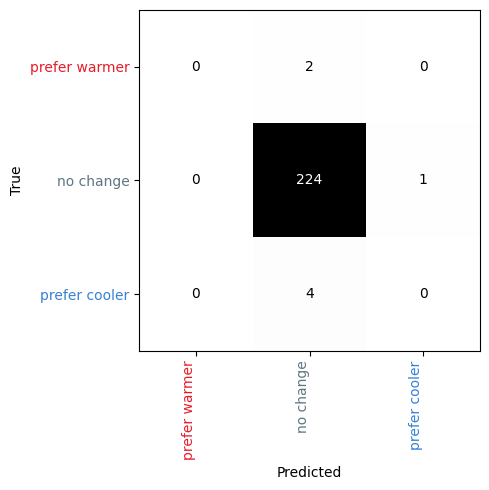

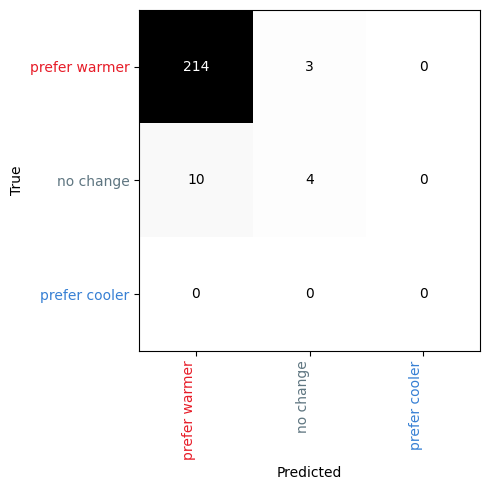

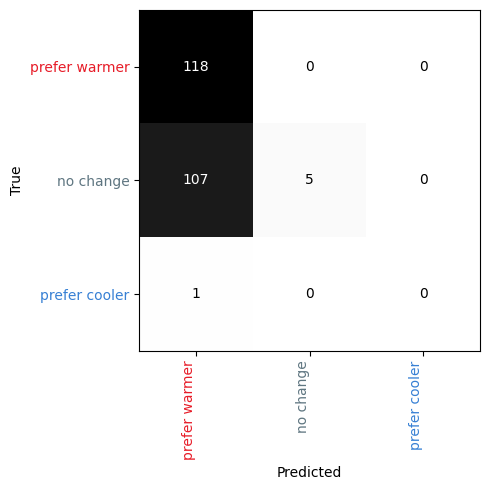

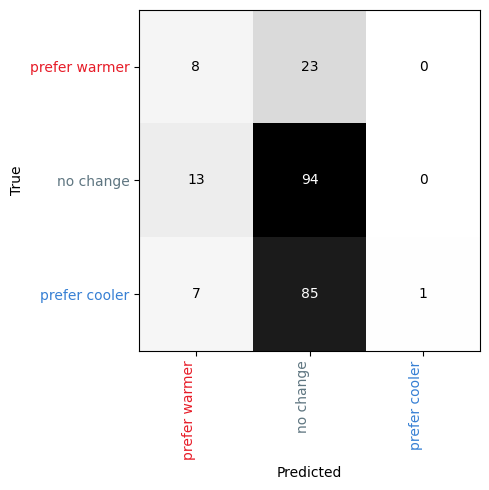

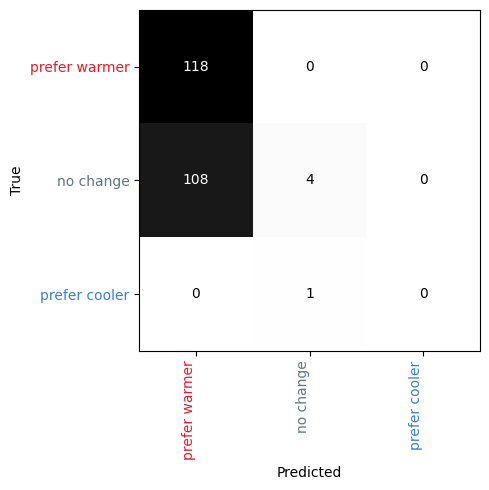

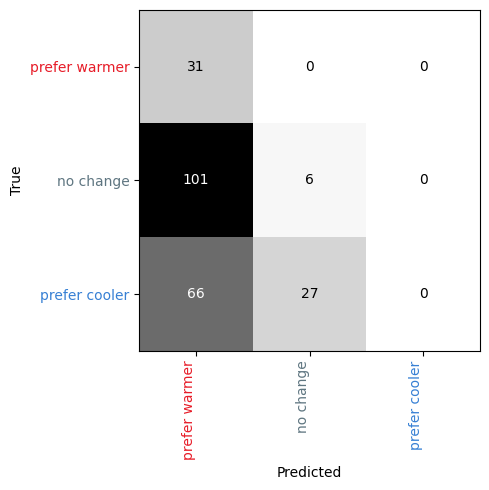

In [10]:
# PersonAI per-person
plot_examples("PersonAI", "Majority Class", P_BEST_COHORT_ALL, n_users=2, filename="personai_confusion_matrix_majority_class_user", cohorts=True, exp_path=personai_best_exp, majority=True)
plot_examples("PersonAI", "PCM – Best users", all_user_path=P_PCM_ALL, users=pcm_personai_best_users, n_users=3, filename="personai_confusion_matrix_pcm_best_user")
plot_examples("PersonAI", "PCM – Balanced users", all_user_path=P_PCM_ALL, users=pcm_personai_balanced_users, n_users=3, filename="personai_confusion_matrix_pcm_balanced_user")
plot_examples("PersonAI", "PCM – Imbalanced users", all_user_path=P_PCM_ALL, users=pcm_personai_imbalanced_users, n_users=3, filename="personai_confusion_matrix_pcm_imbalanced_user")
plot_examples("PersonAI", "Best Cohort", P_BEST_COHORT_ALL, n_users=2,filename="personai_confusion_matrix_cross_dist_cohort_user", cohorts=True, exp_path=personai_best_exp)
plot_examples("PersonAI", "Baseline Cohort", P_BEST_COHORT_ALL, n_users=2,filename="personai_confusion_matrix_baseline_cohort_user", cohorts=True, exp_path=personai_best_exp)

# DORN per-person
plot_examples("DORN", "Majority Class", D_BEST_COHORT_ALL, n_users=2, filename="dorn_confusion_matrix_majority_class_user", cohorts=True, exp_path=dorn_best_exp, majority=True)
plot_examples("DORN", "PCM – Best users", all_user_path=D_PCM_ALL, users=pcm_dorn_best_users, n_users=3, filename="dorn_confusion_matrix_pcm_best_user")
plot_examples("DORN", "PCM – Balanced users", all_user_path=D_PCM_ALL, users=pcm_dorn_balanced_users, n_users=3, filename="dorn_confusion_matrix_pcm_balanced_user")
plot_examples("DORN", "PCM – Imbalanced users", all_user_path=D_PCM_ALL, users=pcm_dorn_imbalanced_users, n_users=3, filename="dorn_confusion_matrix_pcm_imbalanced_user")
plot_examples("DORN", "Best Cohort", D_BEST_COHORT_ALL, n_users=2,filename="dorn_confusion_matrix_cross_dist_cohort_user", cohorts=True, exp_path=dorn_best_exp)
plot_examples("DORN", "Baseline Cohort", D_BEST_COHORT_ALL, n_users=2,filename="dorn_confusion_matrix_baseline_cohort_user", cohorts=True, exp_path=dorn_best_exp, baseline=True)